https://colab.research.google.com/drive/119krag69CpWdpzkZZhsWqOAzJETWjQ8j#scrollTo=H0m7PctnVzF2

https://github.com/611noorsaeed/Real-Time-Image-Classification-with-MobileNetV2-Deep-Learning-Detection-System/tree/main

In [1]:
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input, decode_predictions
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# Load pre-trained MobileNetV2 model
model = MobileNetV2(weights='imagenet')

# Tải một ảnh mẫu từ internet để thử nghiệm bằng cách giả lập User-Agent
import urllib.request
img_url = "https://upload.wikimedia.org/wikipedia/commons/3/3a/Cat03.jpg"
img_path = "cat.jpg"

req = urllib.request.Request(
    img_url,
    headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
)

with urllib.request.urlopen(req) as response, open(img_path, 'wb') as out_file:
    out_file.write(response.read())

# Load and preprocess the image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)

In [5]:
# Predict the class of the image
predictions = model.predict(img_array)

# Decode the predictions into class names
decoded_predictions = decode_predictions(predictions, top=3)[0]

# Display the top 3 predictions with their scores
for i, (imagenet_id, label, score) in enumerate(decoded_predictions):
    print(f"{i + 1}. {label}: {score * 100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1. tiger_cat: 55.73%
2. tabby: 14.41%
3. Egyptian_cat: 10.84%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


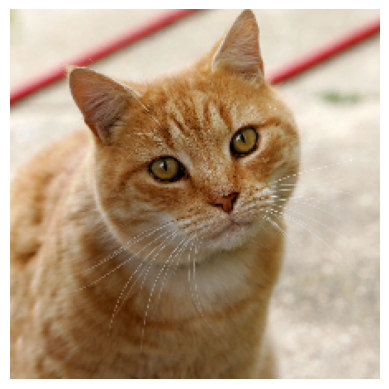

1. tiger_cat: 55.73%
2. tabby: 14.41%
3. Egyptian_cat: 10.84%
4. lynx: 2.75%
5. carton: 0.74%


In [7]:
def predict_image_class(img_path):
    # Load and preprocess the image
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)

    # Predict the class of the image
    predictions = model.predict(img_array)

    # Decode the predictions into class names
    decoded_predictions = decode_predictions(predictions, top=5)[0]

    # Display the image
    plt.imshow(img)
    plt.axis('off')  # Hide axis
    plt.show()

    # Display the top predictions with their scores
    for i, (imagenet_id, label, score) in enumerate(decoded_predictions):
        print(f"{i + 1}. {label}: {score * 100:.2f}%")

# Kiểm tra hàm với ảnh mẫu 'cat.jpg' đã có sẵn
img_path = "cat.jpg"
predict_image_class(img_path)

In [8]:
img_path = "Dataset/vehicals//124_jpeg.rf.e26700cb3f728880123320a3a29f6631.jpg"
predict_image_class(img_path)

FileNotFoundError: [Errno 2] No such file or directory: 'Dataset/vehicals//124_jpeg.rf.e26700cb3f728880123320a3a29f6631.jpg'